In [1]:

%pip install seaborn
%matplotlib inline

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np



Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [3]:
cat_freq = df['category'].value_counts()
cat_freq.head(10)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Manicure & Pedicure Products               18940
Skin Care                                  18769
Make-up                                    18756
Hair Care                                  18735
Fragrances                                 18564
Name: count, dtype: int64

In [4]:
top5 = cat_freq.head(5)
print("Top 5 categorías más listadas:")
display(top5)


Top 5 categorías más listadas:


category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

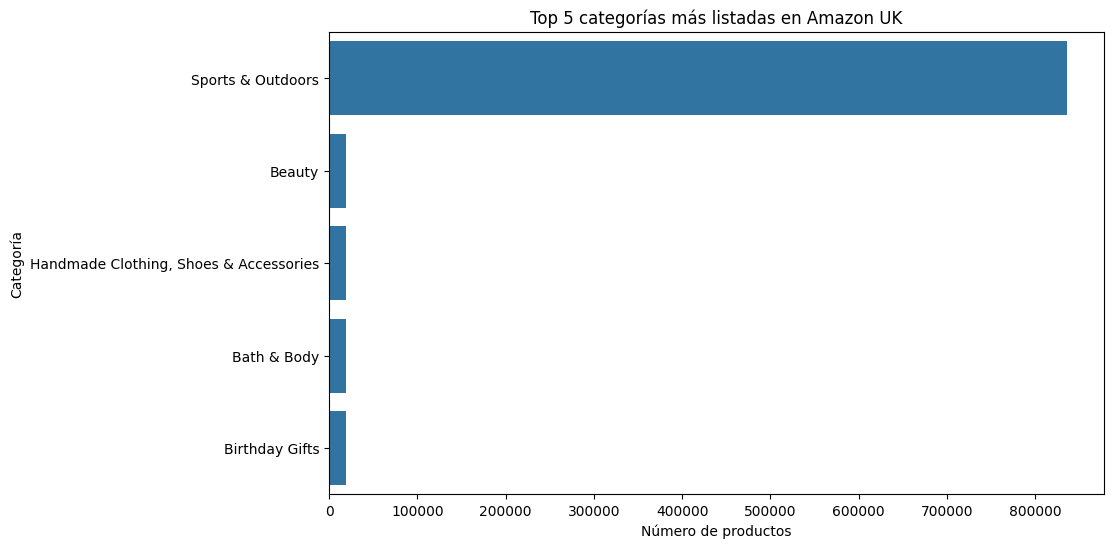

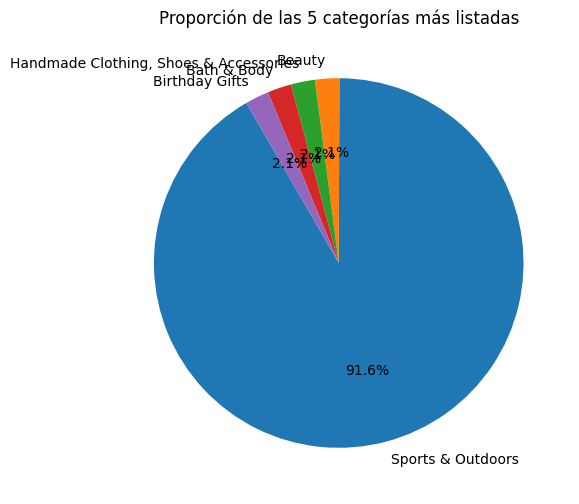

In [5]:
# Barplot general
plt.figure(figsize=(10,6))
sns.barplot(x=top5.values, y=top5.index)
plt.title("Top 5 categorías más listadas en Amazon UK")
plt.xlabel("Número de productos")
plt.ylabel("Categoría")
plt.show()

# Pie chart
plt.figure(figsize=(6,6))
plt.pie(top5.values, labels=top5.index, autopct="%1.1f%%", startangle=120)
plt.title("Proporción de las 5 categorías más listadas")
plt.show()


In [6]:
price = df['price'].dropna()

price_mean   = price.mean()
price_median = price.median()
price_mode   = price.mode().iloc[0] if not price.mode().empty else np.nan

print(f"Mean (average): £{price_mean:,.2f}")
print(f"Median        : £{price_median:,.2f}")
print(f"Mode (most common): £{price_mode:,.2f}")


Mean (average): £89.24
Median        : £19.09
Mode (most common): £9.99


In [7]:
price_var   = price.var()
price_std   = price.std()
price_min   = price.min()
price_max   = price.max()
price_range = price_max - price_min
q1, q3      = price.quantile([0.25, 0.75])
price_iqr   = q3 - q1

print(f"Variance: {price_var:,.2f}")
print(f"Std Dev : {price_std:,.2f}")
print(f"Range   : £{price_range:,.2f} (min=£{price_min:.2f}, max=£{price_max:.2f})")
print(f"IQR     : £{price_iqr:,.2f} (Q1=£{q1:.2f}, Q3=£{q3:.2f})")



Variance: 119,445.49
Std Dev : 345.61
Range   : £100,000.00 (min=£0.00, max=£100000.00)
IQR     : £36.00 (Q1=£9.99, Q3=£45.99)


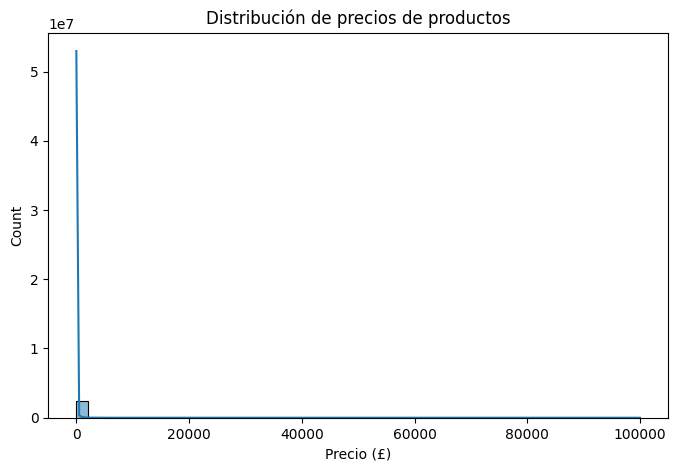

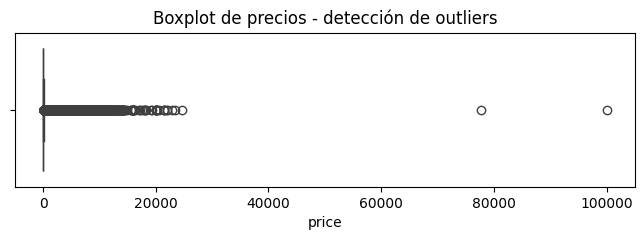

In [8]:
# Histograma
plt.figure(figsize=(8,5))
sns.histplot(df['price'], bins=50, kde=True)
plt.title("Distribución de precios de productos")
plt.xlabel("Precio (£)")
plt.show()

# Boxplot
plt.figure(figsize=(8,2))
sns.boxplot(x=df['price'])
plt.title("Boxplot de precios - detección de outliers")
plt.show()


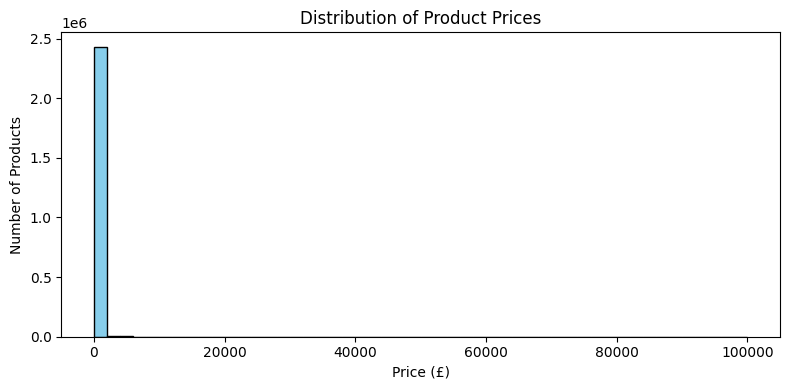

In [9]:
plt.figure(figsize=(8,4))
plt.hist(price, bins=50, color='skyblue', edgecolor='black')
plt.title('Distribution of Product Prices')
plt.xlabel('Price (£)')
plt.ylabel('Number of Products')
plt.tight_layout()
plt.show()

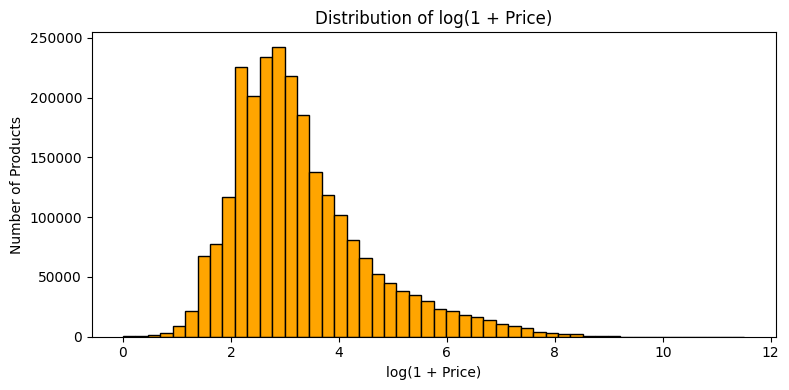

In [10]:
plt.figure(figsize=(8,4))
plt.hist(np.log1p(price), bins=50, color='orange', edgecolor='black')
plt.title('Distribution of log(1 + Price)')
plt.xlabel('log(1 + Price)')
plt.ylabel('Number of Products')
plt.tight_layout()
plt.show()


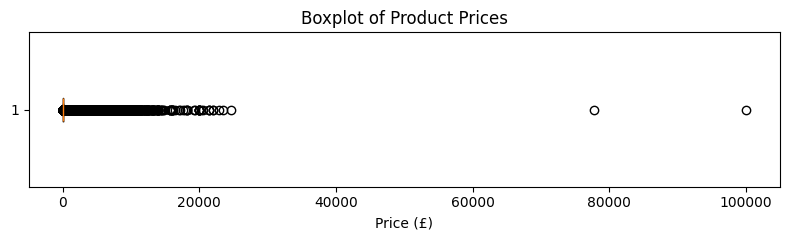

In [11]:
plt.figure(figsize=(8,2.5))
plt.boxplot(price, vert=False, showfliers=True)
plt.title('Boxplot of Product Prices')
plt.xlabel('Price (£)')
plt.tight_layout()
plt.show()


Findings on Product Pricing

The mean price (£89) is much higher than the median (£19), showing a strong right skew in the data.

The range (£0–100,000) and standard deviation (£345) confirm extremely high variability in prices.

The histogram is hard to interpret because a few very expensive products stretch the scale.

Applying a log transformation makes the distribution easier to read and shows that most items are between £5 and £50.

The boxplot reveals numerous high-end outliers, confirming that while most products are low-priced, a few are exceptionally expensive.

Overall, Amazon UK’s pricing distribution is highly uneven, dominated by low-cost items with rare premium listings.